# Hotel Booking Demand — Exploratory Data Analysis

## Project Overview
This project explores hotel booking data using Python, Pandas, and Matplotlib.

## Objectives
- Understand the dataset's structure and data types.
- Identify and analyze missing values.
- Explore numerical and categorical variables.
- Create visualizations to investigate booking patterns.
- Summarize key findings from the data.

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set visualization defaults
sns.set_theme(style="whitegrid")

# Load the dataset
data_path = Path("data/raw/hotel_bookings.csv")
df = pd.read_csv(data_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 1. Structural Overview

This section examines the dataset's dimensions, column data types,
memory usage, and sample records to understand its structure.

In [19]:
# 1. Display the dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 119390
Number of columns: 32


In [15]:
# 2. Display the first five rows
display(df.head())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [16]:
# 3. Display the last five rows
display(df.tail())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


In [17]:
# 4. Inspect column names and data types
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [18]:
# 5. Calculate memory usage
memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"\nTotal memory usage: {memory_mb:.2f} MB")


Total memory usage: 93.90 MB


## 2. Missing Value Analysis

In [21]:
# Calculate missing values
missing_count = df.isnull().sum()
missing_percentage = (df.isnull().mean() * 100).round(2)

In [22]:
# Combine results into a DataFrame
missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_percentage
})

In [23]:
# Display only columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Percentage (%)", ascending=False)

display(missing_summary)

,Missing Count,Missing Percentage (%)
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


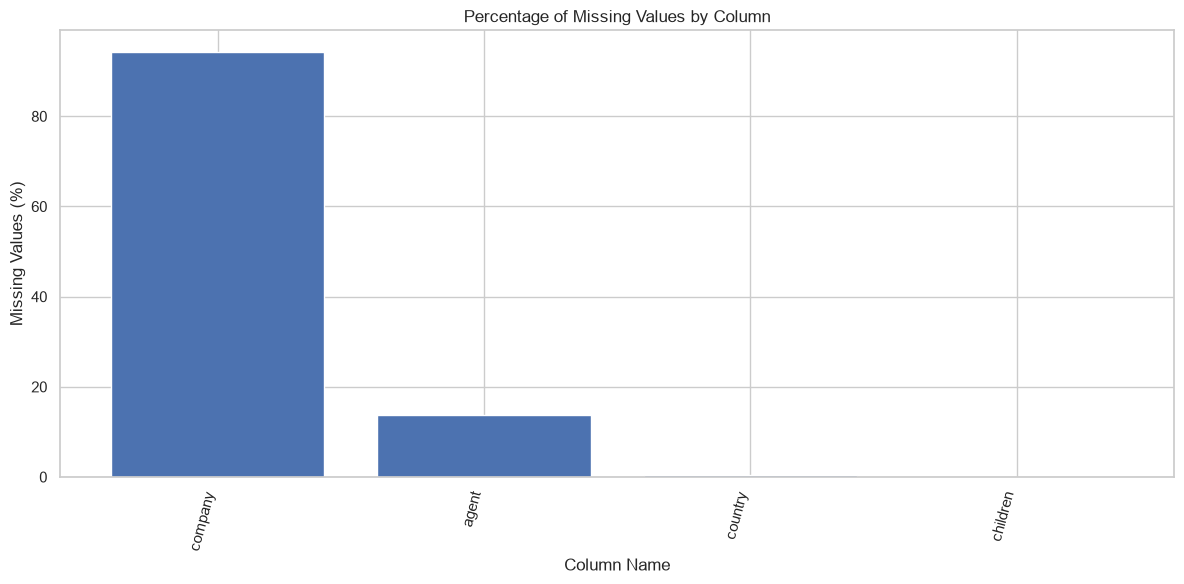

In [26]:
# Missing Value Visualization by percentage
if not missing_summary.empty:
    plt.figure(figsize=(12, 6))

    plt.bar(
        missing_summary.index,
        missing_summary["Missing Percentage (%)"]
    )

    plt.title("Percentage of Missing Values by Column")
    plt.xlabel("Column Name")
    plt.ylabel("Missing Values (%)")
    plt.xticks(rotation=75, ha="right")

    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the dataset.")

### Observations

- The dataset contains missing values in **4 columns**: `company`, `agent`, `country`, and `children`.
- The `company` column has the highest proportion of missing values, with **112,593 missing values (94.31%)**.
- The `agent` column contains **16,340 missing values (13.69%)**, while `country` has **488 missing values (0.41%)**.
- The `children` column contains only **4 missing values**, representing a very small proportion of the dataset.
- These results indicate that missing data is concentrated mainly in the `company` column. The reasons for the missing values should be considered before deciding how to handle them during data preparation.

## 3. Summary Statistics

In [27]:
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate summary statistics
display(numeric_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [28]:
display(
    numeric_df.describe().T
    .join(numeric_df.median().rename("median"))
)

,count,mean,std,min,25%,50%,75%,max,median
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0,0.000
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0,69.000
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0,2016.000
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0,28.000
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0,16.000
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0,1.000
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0,2.000
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0,2.000
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0,0.000
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0,0.000


### Categorical Value Counts

In [29]:
# Explore important categorical columns
categorical_columns = [
    "hotel",
    "is_canceled",
    "market_segment",
    "distribution_channel",
    "customer_type",
    "deposit_type"
]

for column in categorical_columns:
    print(f"\nValue counts for {column}:")
    display(df[column].value_counts(dropna=False).to_frame("Count"))


Value counts for hotel:


,Count
hotel,
City Hotel,79330
Resort Hotel,40060



Value counts for is_canceled:


,Count
is_canceled,
0,75166
1,44224



Value counts for market_segment:


...

,Count
distribution_channel,
TA/TO,97870
Direct,14645
Corporate,6677
GDS,193
Undefined,5



Value counts for customer_type:


,Count
customer_type,
Transient,89613
Transient-Party,25124
Contract,4076
Group,577



Value counts for deposit_type:


,Count
deposit_type,
No Deposit,104641
Non Refund,14587
Refundable,162


### Observations from Summary Statistics

- The dataset contains **119,390 hotel booking records**. Most numerical columns have complete records, while the `children` column has 119,386 non-missing values.

- The average booking lead time is approximately **104 days**, while the median is **69 days**. This difference suggests that some bookings have considerably longer lead times than others.

- The average daily rate (`adr`) is approximately **101.83**, with a median of **94.58**. The mean is higher than the median, suggesting a right-skewed distribution influenced by higher room rates.

- The `stays_in_week_nights` column has a mean of **2.50 nights**, compared with approximately **0.93 nights** for weekend stays. This indicates that weekday nights contribute more to the average length of stay.

- The `total_of_special_requests` column has a median of **0** and a mean of approximately **0.57**, indicating that at least half of the bookings have no special requests.

- The `company` column has only **6,797 non-missing values**, compared with 119,390 total records. This confirms that company information is unavailable for most bookings and requires further consideration during data preparation.

## 4. Data Visualizations

#### 4.1 How many bookings were canceled?

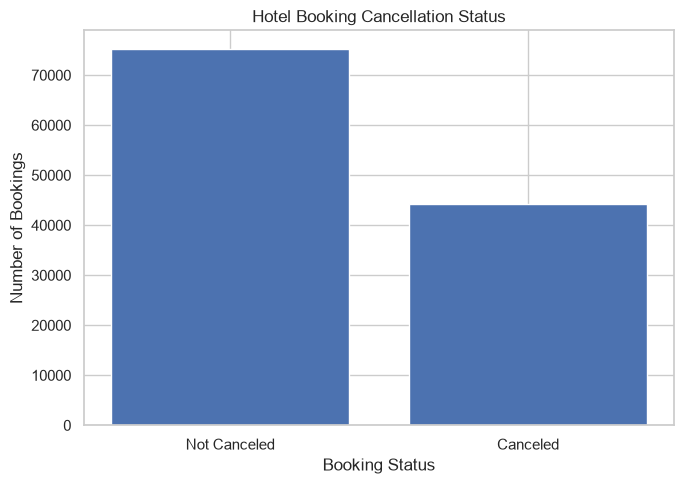

In [30]:
cancellation_counts = df["is_canceled"].map({
    0: "Not Canceled",
    1: "Canceled"
}).value_counts()

plt.figure(figsize=(7, 5))
plt.bar(cancellation_counts.index, cancellation_counts.values)

plt.title("Hotel Booking Cancellation Status")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()

Interpretation: The chart compares canceled and non-canceled bookings. Non-canceled bookings are more common, with over 70,000 bookings, while approximately 45,000 bookings were canceled. This indicates that most hotel bookings in the dataset were not canceled.

### 2.Which hotel type receives more bookings?

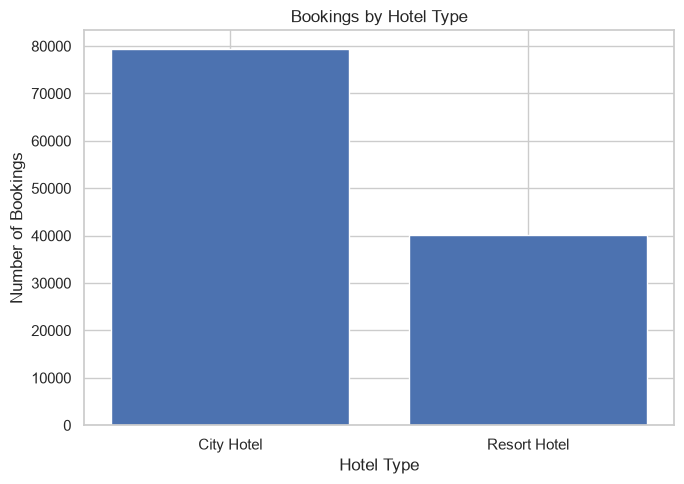

In [31]:
hotel_counts = df["hotel"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(hotel_counts.index, hotel_counts.values)

plt.title("Bookings by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()

**Interpretation:** The chart compares the number of bookings for City Hotels and Resort Hotels. City Hotels received nearly **80,000 bookings**, while Resort Hotels received **40,000 bookings**. This indicates that City Hotels were booked about twice as often as Resort Hotels in this dataset.

### 3.What does the average daily rate look like?

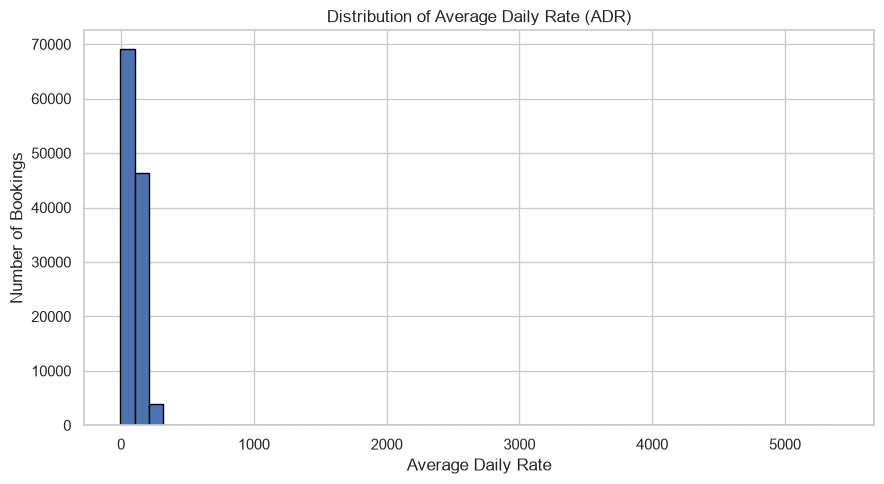

In [32]:
plt.figure(figsize=(9, 5))
plt.hist(df["adr"].dropna(), bins=50, edgecolor="black")

plt.title("Distribution of Average Daily Rate (ADR)")
plt.xlabel("Average Daily Rate")
plt.ylabel("Number of Bookings")
plt.tight_layout()
plt.show()

**Interpretation:** The histogram shows the distribution of Average Daily Rate (ADR) across hotel bookings. Most bookings are concentrated at lower ADR values, while a small number of bookings have extremely high rates, creating a long tail on the right. These unusually high values may represent outliers that require further investigation.

### 4.Which months have the highest average daily rates?

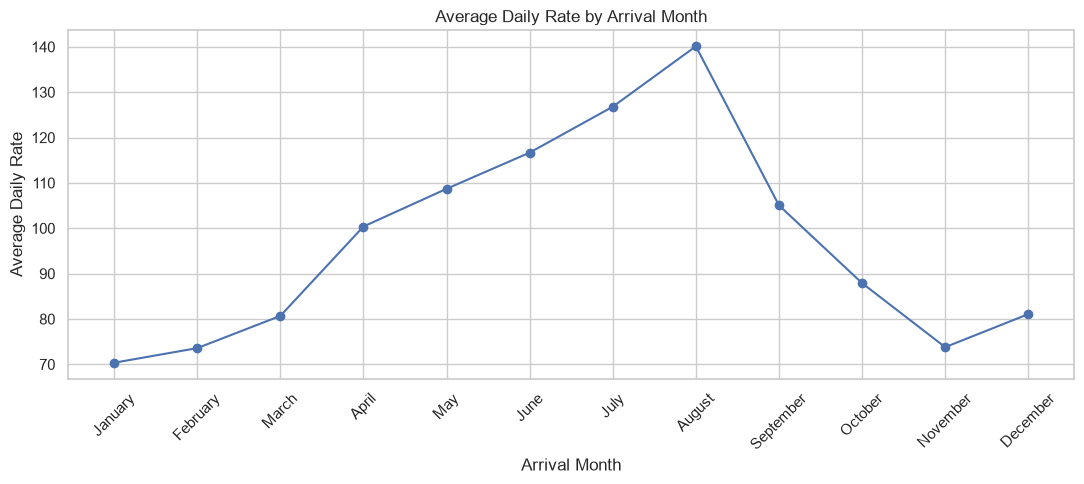

In [33]:
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

monthly_adr = (
    df.groupby("arrival_date_month", observed=False)["adr"]
    .mean()
    .reindex(month_order)
)

plt.figure(figsize=(11, 5))
plt.plot(monthly_adr.index, monthly_adr.values, marker="o")

plt.title("Average Daily Rate by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Average Daily Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Interpretation: The chart compares the average daily rate (ADR) across arrival months. January has the lowest average rate at approximately 70, while August has the highest average rate at approximately 140. A notable pattern is that the average daily rate generally increases from January to August and then gradually decreases toward November, suggesting seasonal variations in hotel pricing.

### 5.How does lead time relate to cancellations?

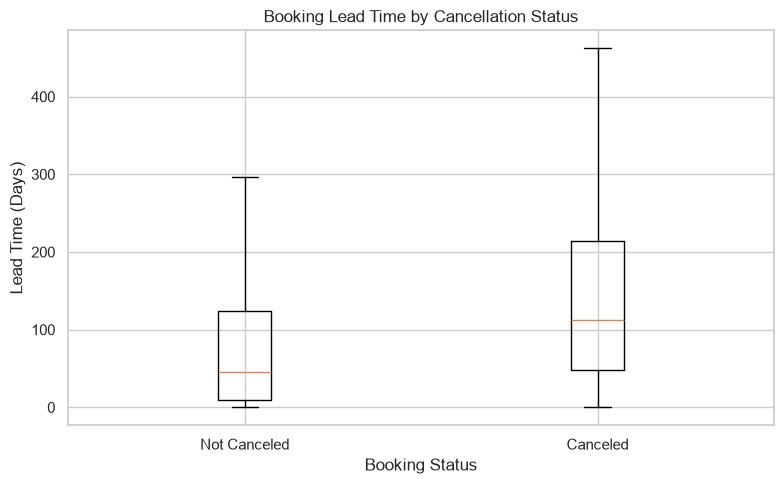

In [34]:
plt.figure(figsize=(8, 5))

lead_time_data = [
    df.loc[df["is_canceled"] == 0, "lead_time"].dropna(),
    df.loc[df["is_canceled"] == 1, "lead_time"].dropna()
]

plt.boxplot(
    lead_time_data,
    tick_labels=["Not Canceled", "Canceled"],
    showfliers=False
)

plt.title("Booking Lead Time by Cancellation Status")
plt.xlabel("Booking Status")
plt.ylabel("Lead Time (Days)")
plt.tight_layout()
plt.show()

**Interpretation:** The box plot shows that canceled bookings generally have a longer lead time than non-canceled bookings. The median lead time for canceled bookings is approximately **110 days**, compared with about **45 days** for non-canceled bookings. The canceled bookings also show a wider spread, indicating greater variation in how far in advance bookings are made. This suggests that bookings made further in advance may be more likely to be canceled.

### 6.Which factors are correlated with one another?

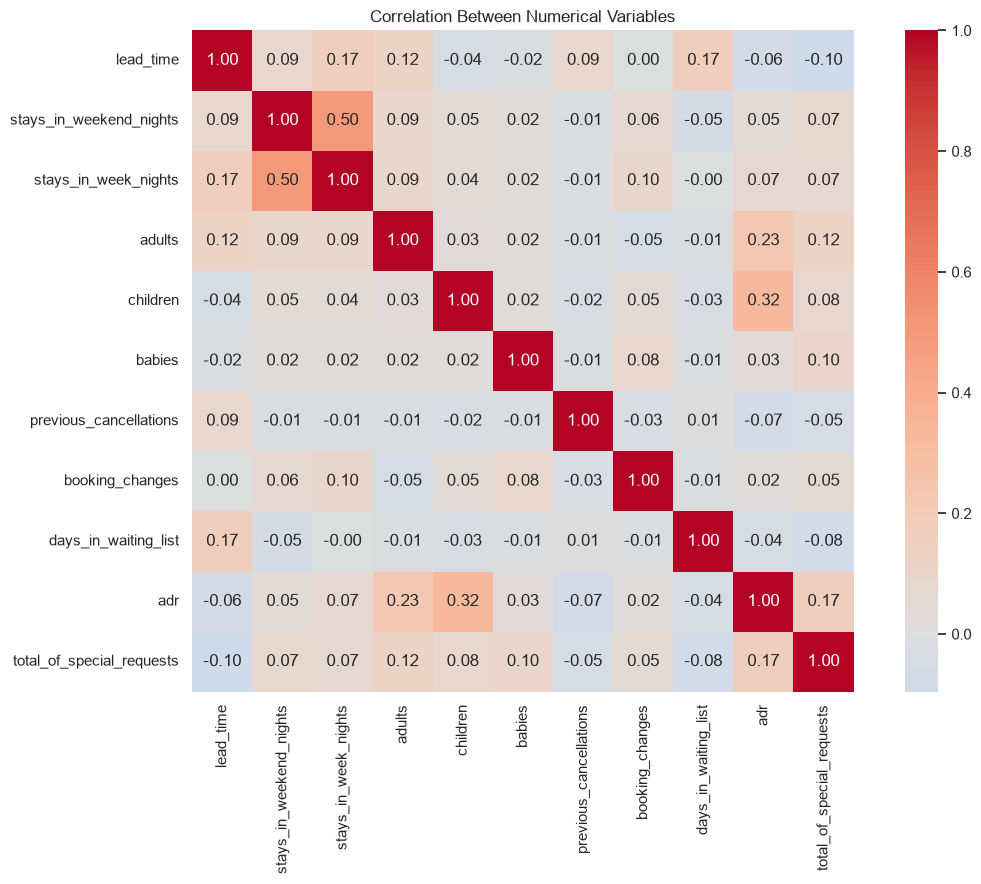

In [35]:
correlation_columns = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "booking_changes",
    "days_in_waiting_list",
    "adr",
    "total_of_special_requests"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    square=True
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

**Interpretation:** The heatmap shows that most numerical variables have weak linear correlations with one another. The strongest positive correlation is **0.50** between weekend-night stays and weekday-night stays. The number of children has a moderate positive correlation with the average daily rate (ADR), at **0.32**, while adults and ADR show a weaker positive correlation of **0.23**. Overall, the chart indicates that most variable pairs have little linear relationship, and correlation does not necessarily imply causation.


## 6.Final Findings and Conclusion

### Key Findings

1. **Booking Cancellation:** The dataset contains over 70,000 non-canceled bookings and approximately 45,000 canceled bookings, indicating that non-canceled bookings are more common.

2. **Hotel Type Preference:** City Hotels received nearly 80,000 bookings, while Resort Hotels received approximately 40,000 bookings. City Hotels were booked about twice as often as Resort Hotels.

3. **Seasonal Pricing:** The average daily rate generally increases from January to August, reaching its highest level in August at approximately 140, before declining toward November.

4. **Booking Lead Time:** Canceled bookings generally have longer lead times than non-canceled bookings. This suggests that bookings made further in advance may be associated with a higher likelihood of cancellation.

5. **Missing Values and Correlations:** The `company` column has the most missing values, at 94.31%. The correlation heatmap also shows a positive correlation of 0.50 between weekend-night stays and weekday-night stays.

### Conclusion

This exploratory data analysis revealed useful patterns in hotel bookings, including cancellation behavior, hotel preferences, seasonal pricing, and booking lead times. It also identified missing data that may require attention before further analysis. These findings can help guide future investigations into booking cancellations, customer behavior, and hotel pricing strategies.
